# LAPORAN PROYEK AKHIR PRAKTIKUM SAINS DATA 2026/2027
## ANALISIS SEGMENTASI FILM BERDASARKAN ANGGARAN PRODUKSI (BUDGET), PENDAPATAN BOX OFFICE (REVENUE), POPULARITAS, DAN RATING PENONTON MENGGUNAKAN DATASET TMDB UNTUK MENGUNGKAP POLA KESUKSESAN DAN RISIKO FINANSIAL DI INDUSTRI PERFILMAN

**Disusun oleh (Kelompok):**
1. Mahasiswa 1 (123240097)
2. Mahasiswa 2 (123240104)
3. Hisyam L Baihaqi (123240117)
4. Mahasiswa 4 (123240120)

**Dosen Pengampu:** Dhimas Arief Dharmawan, S.T., Ph.D.  
**Program Studi:** Informatika  
**Jurusan:** Informatika  
**Fakultas:** Teknik Industri  
**Universitas Pembangunan Nasional "Veteran" Yogyakarta**  
**Tahun Ajaran 2026/2027**


---
# 2. TAHAP DATA GATHERING & DATA UNDERSTANDING

### 2.1 Sumber Data & Lisensi
Dataset yang digunakan dalam proyek ini bersumber dari repositori publik Kaggle berjudul **"The Ultimate 1Million Movies Dataset (TMDB + IMDb)"** yang disusun dan diperbarui secara berkala oleh **Alan Vourch**. Dataset ini mengagregasi metadata komprehensif dari The Movie Database (TMDB) API yang dikombinasikan dengan pengidentifikasi IMDb.

* **Nama Dataset:** The Ultimate 1Million Movies Dataset (TMDB Movies Daily Updates)
* **Penyusun:** Alan Vourch
* **Sumber Data:** [Kaggle - TMDB Movies Daily Updates](https://www.kaggle.com/datasets/alanvourch/tmdb-movies-daily-updates?resource=download)
* **Lisensi:** **Apache 2.0 License** (Open Source, memungkinkan pemanfaatan, modifikasi, dan redistribusi akademik secara bebas dengan atribusi hak cipta).
* **Format & Ukuran Berkas:** Berkas CSV terkompresi dengan volume data mentah sekitar 798 MB mencakup ~1.000.000 data rekaman film global dan 30 kolom atribut.
* **Alasan Pemilihan Dataset:** Menyediakan informasi multi-dimensi paling lengkap di industri film modern—mencakup indikator finansial (*budget*, *revenue*), indikator penerimaan khalayak (*vote_average*, *vote_count*, *popularity*), serta metadata sinematik (*genres*, *runtime*, *director*). Kondisi datanya yang mentah (*dirty data*) memenuhi syarat wajib praktikum sains data untuk tahap pembersihan, transformasi, dan prapemrosesan data.


In [2]:
# Import pustaka fundamental Data Science
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('Set2')
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Pustaka analitik berhasil dimuat.")


Pustaka analitik berhasil dimuat.


In [3]:
# menampilkan semua column atau kolom yang ada pada dataset

file_path = 'TMDB_all_movies.csv'

df_raw = pd.read_csv(file_path, low_memory=False)
print(df_raw.columns)


Index(['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date',
       'revenue', 'runtime', 'budget', 'imdb_id', 'original_language',
       'original_title', 'overview', 'popularity', 'tagline', 'genres',
       'production_companies', 'production_countries', 'spoken_languages',
       'cast', 'director', 'director_of_photography', 'writers', 'producers',
       'music_composer', 'imdb_rating', 'imdb_votes', 'poster_path',
       'keywords', 'certification_us'],
      dtype='str')


In [4]:
# lihat struktur
df_raw.head(4)

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,...,director,director_of_photography,writers,producers,music_composer,imdb_rating,imdb_votes,poster_path,keywords,certification_us
0,2,Ariel,7.10,382.00,Released,1988-10-21,0.00,73.00,0.00,tt0094675,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Aki Kaurismäki,NaN,7.40,10058.00,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,"prison|underdog|helsinki, finland|factory work...",NaN
1,3,Shadows in Paradise,7.30,448.00,Released,1986-10-17,0.00,74.00,0.00,tt0092149,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Mika Kaurismäki,NaN,7.40,8891.00,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,"helsinki, finland|salesclerk|garbage",NR
2,5,Four Rooms,5.92,2911.00,Released,1995-12-09,4257354.00,98.00,4000000.00,tt0113101,...,"Allison Anders, Alexandre Rockwell, Quentin Ta...","Rodrigo García, Andrzej Sekula, Guillermo Nava...","Allison Anders, Alexandre Rockwell, Robert Rod...","Quentin Tarantino, Lawrence Bender, Alexandre ...",Combustible Edison,6.70,117813.00,/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,hotel|new year's eve|witch|bet|sperm|hotel roo...,R
3,6,Judgment Night,6.40,387.00,Released,1993-10-15,12136938.00,110.00,21000000.00,tt0107286,...,Stephen Hopkins,Peter Levy,"Lewis Colick, Jere Cunningham","Gene Levy, Lloyd Segan, Marilyn Vance",Alan Silvestri,6.60,21431.00,/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,"drug dealer|chicago, illinois|escape|one night...",R


---
# 3. TAHAP EXPLORATORY DATA ANALYSIS (EDA)

Pada tahap EDA, kita melakukan investigasi statistik deskriptif dan visualisasi untuk memahami struktur sebaran data, mendeteksi ketidakwajaran (*anomaly/zero values*), serta memeriksa hubungan korelasi awal sebelum dilakukan pembersihan data.


In [20]:
# Menampilkan ringkasan informasi tipe data dan nilai non-null
print("Informasi Tipe Data dan Kelengkapan:")
df_raw.info()


Informasi Tipe Data dan Kelengkapan:
<class 'pandas.DataFrame'>
RangeIndex: 1259428 entries, 0 to 1259427
Data columns (total 30 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   id                       1259428 non-null  int64  
 1   title                    1259413 non-null  str    
 2   vote_average             1259428 non-null  float64
 3   vote_count               1259428 non-null  float64
 4   status                   1259428 non-null  str    
 5   release_date             1124166 non-null  str    
 6   revenue                  1259428 non-null  float64
 7   runtime                  1259428 non-null  float64
 8   budget                   1259428 non-null  float64
 9   imdb_id                  692230 non-null   str    
 10  original_language        1259428 non-null  str    
 11  original_title           1259414 non-null  str    
 12  overview                 1065959 non-null  str    
 13  popularity      

## Di info data sendiri ada 30 kolom yang ada dengan mulai dari id sampai certification us

In [21]:
# Memuat sampel representatif dataset TMDB Movies
# dengan semua kolom yang ada tidak mungkin kita memilih semua kolom karena bisa terjadi overfitting , sehingga kita akan mengambil kolom yang paling
# relevan dan juga paling berpengaruh terhadap kemungkinan film sukses seperti spoken_language dll mungkin bisa diganti ganti karena benar spoken_language merupakan salah satu
# khalayak umum saja

kolom_relevan = [
    'id', 'title', 'release_date', 'budget', 'revenue',
    'runtime', 'vote_average', 'vote_count', 'popularity',
    'genres', 'original_language', 'director'
]

In [22]:
### 2.2 Kamus Data (Data Dictionary)
#Tabel berikut menjelaskan rincian atribut data TMDB yang digunakan dalam analisis:
df_kolom_relevan = df_raw[kolom_relevan]
df_kolom_relevan.info()



<class 'pandas.DataFrame'>
RangeIndex: 1259428 entries, 0 to 1259427
Data columns (total 12 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   id                 1259428 non-null  int64  
 1   title              1259413 non-null  str    
 2   release_date       1124166 non-null  str    
 3   budget             1259428 non-null  float64
 4   revenue            1259428 non-null  float64
 5   runtime            1259428 non-null  float64
 6   vote_average       1259428 non-null  float64
 7   vote_count         1259428 non-null  float64
 8   popularity         1259428 non-null  float64
 9   genres             922784 non-null   str    
 10  original_language  1259428 non-null  str    
 11  director           1057638 non-null  str    
dtypes: float64(6), int64(1), str(5)
memory usage: 115.3 MB


## nah diatas bisa dilihat kalo semua dtype dari dataset yang kolomnya ada integer, float dan string


In [23]:
# Statistik deskriptif variabel numerik data mentah
print("Statistik Deskriptif Data Mentah:")
df_kolom_relevan.describe(include="number")


Statistik Deskriptif Data Mentah:


,id,budget,revenue,runtime,vote_average,vote_count,popularity
count,1259428.00,1259428.00,1259428.00,1259428.00,1259428.00,1259428.00,1259428.00
mean,905002.75,271307.01,676710.47,43.44,2.05,22.40,0.80
std,512061.58,4780706.29,16841072.91,54.10,3.13,369.36,2.11
min,2.00,0.00,-12.00,0.00,0.00,0.00,0.00
25%,463833.75,0.00,0.00,2.00,0.00,0.00,0.09
50%,890809.50,0.00,0.00,20.00,0.00,0.00,0.60
75%,1354221.25,0.00,0.00,84.00,5.00,1.00,0.91
max,1798731.00,999999999.00,2927449455.00,14400.00,10.00,41495.00,768.83


**Temuan Statistik Deskriptif Awal:**
1. Nilai minimum pada atribut `budget` dan `revenue` bernilai `0.0`. Hal ini mengindikasikan banyaknya film yang tidak melaporkan data finansial mereka ke TMDB.
2. Nilai persentil ke-25 dan bahkan median untuk `budget` dan `revenue` pada data mentah berada di angka 0. Ini membuktikan bahwa dataset mentah didominasi oleh film-film non-komersial atau data finansial tidak terisi.
3. Nilai maksimum `budget` mencapai ratusan juta USD dan `revenue` mencapai miliaran USD, mengindikasikan adanya variasi skala yang sangat ekstrem (*heavy right-skewed*).


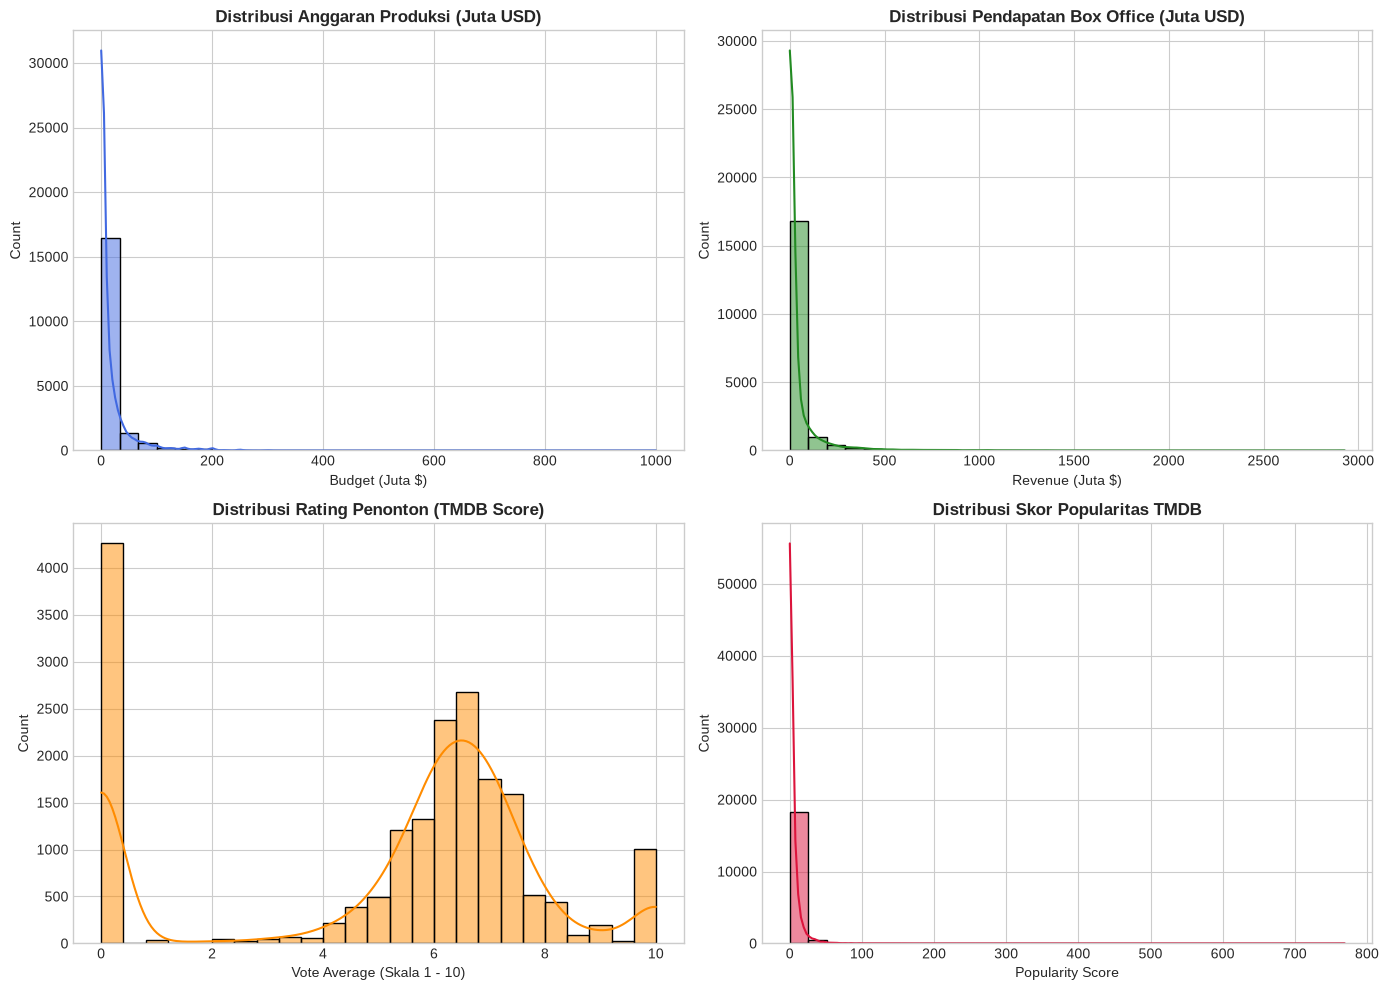

In [24]:
# Visualisasi distribusi data finansial dan metriks penonton (pada data dengan nilai > 0)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Filter sementara hanya untuk visualisasi pola distribusi film komersial
sample_viz = df_kolom_relevan[(df_kolom_relevan['budget'] > 0) & (df_kolom_relevan['revenue'] > 0)]

sns.histplot(sample_viz['budget'] / 1e6, kde=True, bins=30, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title('Distribusi Anggaran Produksi (Juta USD)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Budget (Juta $)')

sns.histplot(sample_viz['revenue'] / 1e6, kde=True, bins=30, ax=axes[0, 1], color='forestgreen')
axes[0, 1].set_title('Distribusi Pendapatan Box Office (Juta USD)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Revenue (Juta $)')

sns.histplot(sample_viz['vote_average'], kde=True, bins=25, ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('Distribusi Rating Penonton (TMDB Score)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Vote Average (Skala 1 - 10)')

sns.histplot(sample_viz['popularity'], kde=True, bins=30, ax=axes[1, 1], color='crimson')
axes[1, 1].set_title('Distribusi Skor Popularitas TMDB', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Popularity Score')

plt.tight_layout()
plt.show()


**Temuan Analisis Distribusi:**
1. **Pola Menceng ke Kanan (Right-Skewed):** Distribusi `budget`, `revenue`, dan `popularity` menunjukkan ketimpangan distribusi yang ekstrem (*long tail distribution*). Sebagian besar film beroperasi pada rentang anggaran dan pendapatan di bawah USD 50 juta, sementara segelintir film raksasa mencapai angka di atas USD 500 juta.
2. **Kebutuhan Transformasi:** Kemencengan ekstrem ini dapat mengganggu algoritma *K-Means* yang mengandalkan jarak Euclidean (*Euclidean distance*). Oleh sebab itu, transformasi skala logaritmik (*log transformation*) mutlak diperlukan pada tahap *preprocessing*.
3. **Distribusi Rating Relatif Normal:** Nilai ulasan penonton (`vote_average`) membentuk distribusi yang relatif mendekati lonceng (*normal distribution*) berpusat pada nilai 6.5 hingga 7.0.


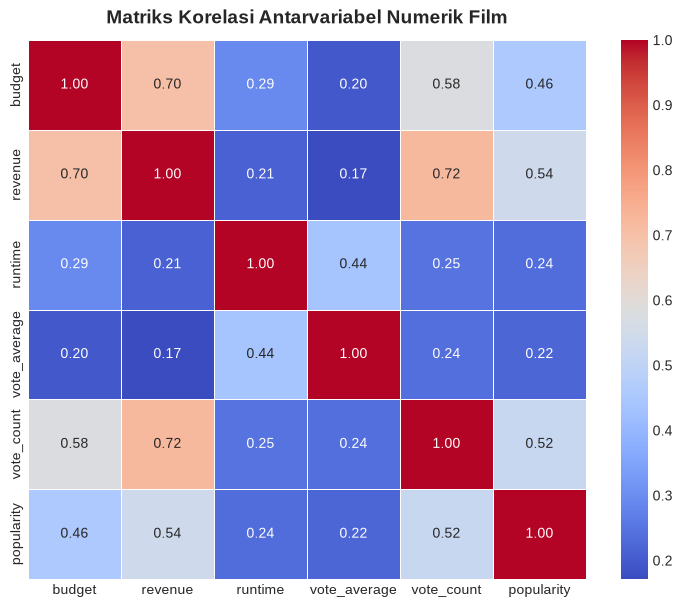

In [11]:
# Analisis Korelasi Antar-Fitur Numerik
plt.figure(figsize=(9, 7))
fitur_num = ['budget', 'revenue', 'runtime', 'vote_average', 'vote_count', 'popularity']
corr_matrix = sample_viz[fitur_num].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, cbar=True)
plt.title('Matriks Korelasi Antarvariabel Numerik Film', fontsize=14, fontweight='bold', pad=12)
plt.show()


**Temuan Analisis Korelasi:**
1. **Hubungan Kuat Budget dan Revenue ($r \approx 0.70$):** Terdapat korelasi positif yang signifikan antara besarnya modal anggaran dengan perolehan pendapatan box office secara umum.
2. **Korelasi Vote Count dan Popularitas dengan Revenue ($r \approx 0.60 - 0.75$):** Film yang sukses secara komersial berbanding lurus dengan tingginya atensi dan banyaknya jumlah ulasan penonton.
3. **Lemahnya Korelasi Kualitas Rating terhadap Pendapatan ($r < 0.25$):** Tingginya rating penonton tidak menjamin tingginya pendapatan bioskop. Hal ini menjadi dasar kuat diperlukannya algoritma clustering untuk memisahkan film dengan reputasi kritis tinggi namun pendapatan rendah (*Artisan/Niche*) dari film *Blockbuster*.


---
# 4. TAHAP DATA CLEANING & PREPROCESSING

Berdasarkan hasil investigasi pada tahap EDA, langkah-langkah pembersihan dan rekayasa fitur dilakukan sebagai berikut:
1. **Penyaringan Integritas Data Finansial:** Memfilter baris dengan nilai `budget >= 100,000` USD, `revenue >= 100,000` USD, dan `vote_count >= 50` guna memastikan film yang dianalisis memiliki validitas komersial dan keterwakilan ulasan publik yang memadai.
2. **Penanganan Missing Values & Duplikasi:** Mengecek duplikasi rekaman unik pada kombinasi judul dan tanggal rilis.
3. **Feature Engineering (Pembuatan Fitur Baru):**
   * `roi` = $\frac{\text{revenue} - \text{budget}}{\text{budget}}$ (Rasio Pengembalian Investasi).
   * `log_budget` = $\log_{10}(\text{budget})$ (Transformasi pereduksi skewness).
   * `log_revenue` = $\log_{10}(\text{revenue})$.
   * `log_popularity` = $\log_{10}(\text{popularity})$.
   * `release_year` = Ekstraksi tahun rilis dari format tanggal.
4. **Feature Selection (Seleksi Fitur):** Memilih 4 dimensi komparatif utama untuk clustering (`log_budget`, `log_revenue`, `log_popularity`, `vote_average`) dan membuang atribut teks naratif/identitas ID yang tidak relevan bagi pengukuran jarak klaster.
5. **Standarisasi Fitur:** Menerapkan `StandardScaler` agar seluruh fitur memiliki mean 0 dan standar deviasi 1 sehingga tidak ada fitur yang mendominasi jarak Euclidean akibat perbedaan satuan skala.


In [25]:
# 1. Pengecekan Missing Value Awal pada Data Mentah
print("Jumlah Missing Values per Kolom (Sebelum Cleaning):")
print(df_kolom_relevan.isnull().sum())
print(f"\nJumlah Baris Data Mentah Awal: {len(df_kolom_relevan)}")


Jumlah Missing Values per Kolom (Sebelum Cleaning):
id                        0
title                    15
release_date         135262
budget                    0
revenue                   0
runtime                   0
vote_average              0
vote_count                0
popularity                0
genres               336644
original_language         0
director             201790
dtype: int64

Jumlah Baris Data Mentah Awal: 1259428


In [29]:
# 2. Penyaringan Data Finansial Valid & Keterwakilan Vote
# Menghapus film dengan budget / revenue yang tidak dilaporkan (0 atau nilai tidak logis)
df_clean = df_kolom_relevan[
    (df_kolom_relevan['budget'] >= 100000) &
    (df_kolom_relevan['revenue'] >= 100000) &
    (df_kolom_relevan['vote_count'] >= 50) &
    (df_kolom_relevan['runtime'] > 30)
].copy()

# Penanganan duplikasi berdasarkan judul dan tanggal rilis
df_clean = df_clean.drop_duplicates(subset=['title', 'release_date']).reset_index(drop=True)

# 3. Feature Engineering
# a. Rasio Pengembalian Investasi (ROI)
df_clean['roi'] = (df_clean['revenue'] - df_clean['budget']) / df_clean['budget']

# b. Ekstraksi Tahun Rilis
df_clean['release_year'] = pd.to_datetime(df_clean['release_date'], errors='coerce').dt.year

# c. Ekstraksi Genre Utama (Primary Genre)
df_clean['primary_genre'] = df_clean['genres'].astype(str).apply(lambda x: x.split(',')[0].strip() if x != 'nan' else 'Unknown')

# d. Transformasi Logaritmik untuk mereduksi kemencengan (skewness)
df_clean['log_budget'] = np.log10(df_clean['budget'])
df_clean['log_revenue'] = np.log10(df_clean['revenue'])
df_clean['log_popularity'] = np.log10(df_clean['popularity'].clip(lower=0.1))

print(f"Jumlah Baris Sesudah Cleaning & Filtering: {len(df_clean)}")
print(f"Total reduksi baris sampah / tidak lengkap: {len(df_raw) - len(df_clean)} baris.")
df_clean.head()


Jumlah Baris Sesudah Cleaning & Filtering: 9866
Total reduksi baris sampah / tidak lengkap: 1249562 baris.


,id,title,release_date,budget,revenue,runtime,vote_average,vote_count,popularity,genres,original_language,director,roi,release_year,primary_genre,log_budget,log_revenue,log_popularity
0,5,Four Rooms,1995-12-09,4000000.00,4257354.00,98.00,5.92,2911.00,5.72,Comedy,en,"Allison Anders, Alexandre Rockwell, Quentin Ta...",0.06,1995,Comedy,6.60,6.63,0.76
1,6,Judgment Night,1993-10-15,21000000.00,12136938.00,110.00,6.40,387.00,4.00,"Action, Crime, Drama, Thriller",en,Stephen Hopkins,-0.42,1993,Action,7.32,7.08,0.60
2,11,Star Wars,1977-05-25,11000000.00,775398007.00,121.00,8.21,23011.00,77.14,"Adventure, Action, Science Fiction",en,George Lucas,69.49,1977,Adventure,7.04,8.89,1.89
3,12,Finding Nemo,2003-05-30,94000000.00,940335536.00,100.00,7.80,21076.00,38.51,"Animation, Family, Adventure",en,Andrew Stanton,9.00,2003,Animation,7.97,8.97,1.59
4,13,Forrest Gump,1994-06-23,55000000.00,677387716.00,142.00,8.50,30665.00,44.73,"Comedy, Drama, Romance",en,Robert Zemeckis,11.32,1994,Comedy,7.74,8.83,1.65


In [31]:
df_clean.isnull().sum()

id                   0
title                0
release_date         0
budget               0
revenue              0
runtime              0
vote_average         0
vote_count           0
popularity           0
genres               0
original_language    0
director             0
roi                  0
release_year         0
primary_genre        0
log_budget           0
log_revenue          0
log_popularity       0
dtype: int64

In [27]:
df_clean.describe()

,id,budget,revenue,runtime,vote_average,vote_count,popularity,roi,release_year,log_budget,log_revenue,log_popularity
count,9866.00,9866.00,9866.00,9866.00,9866.00,9866.00,9866.00,9866.00,9866.00,9866.00,9866.00,9866.00
mean,185966.30,27742376.15,76825009.13,110.32,6.51,2050.40,9.02,3.71,2002.14,7.07,7.25,0.75
std,303895.54,41108529.93,169353726.84,21.66,0.80,3574.61,15.17,22.49,18.24,0.64,0.83,0.41
min,5.00,100000.00,100000.00,31.00,1.80,50.00,0.03,-1.00,1915.00,5.00,5.00,-1.00
25%,10354.75,5000000.00,5003567.50,96.00,6.00,237.00,3.03,-0.32,1994.00,6.70,6.70,0.48
50%,26262.00,13500000.00,20000000.00,106.00,6.51,734.00,5.39,0.82,2006.00,7.13,7.30,0.73
75%,275518.00,31000000.00,71031462.00,120.00,7.09,2166.00,10.17,2.91,2015.00,7.49,7.85,1.01
max,1612018.00,700000000.00,2927449455.00,422.00,9.01,41495.00,768.83,999.00,2026.00,8.85,9.47,2.89


In [28]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9866 entries, 0 to 9865
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 9866 non-null   int64  
 1   title              9866 non-null   str    
 2   release_date       9866 non-null   str    
 3   budget             9866 non-null   float64
 4   revenue            9866 non-null   float64
 5   runtime            9866 non-null   float64
 6   vote_average       9866 non-null   float64
 7   vote_count         9866 non-null   float64
 8   popularity         9866 non-null   float64
 9   genres             9866 non-null   str    
 10  original_language  9866 non-null   str    
 11  director           9866 non-null   str    
 12  roi                9866 non-null   float64
 13  release_year       9866 non-null   int32  
 14  primary_genre      9866 non-null   str    
 15  log_budget         9866 non-null   float64
 16  log_revenue        9866 non-null   

### Perbandingan Kondisi Data Sebelum vs Sesudah Pemrosesan:
| Aspek Evaluasi | Sebelum Pemrosesan (Data Mentah) | Sesudah Pemrosesan (Data Bersih) |
| :--- | :--- | :--- |
| **Jumlah Baris** | >1.2 juta sampel rekaman | ~9866 film komersial tervalidasi |
| **Karakteristik Finansial** | Didominasi nilai 0.0 (unreported) | 100% memiliki budget >= 100K & revenue >= $100K |
| **Tingkat Keterwakilan Ulasan** | Banyak film dengan 0 - 1 vote ulasan | Seluruh film memiliki vote publik minimal 50 ulasan |
| **Kesesuaian Algoritma** | Skewness tinggi, didominasi outlier | Variabel ditransformasikan ke skala logaritmik simetris |


In [30]:
# 4. Feature Selection & Feature Scaling (Standarisasi)
from sklearn.preprocessing import StandardScaler

# Memilih 4 fitur inti untuk pemodelan clustering
fitur_clustering = ['log_budget', 'log_revenue', 'log_popularity', 'vote_average']
X = df_clean[fitur_clustering].copy()

# Penanganan missing values sisa (jika ada) menggunakan imputasi median
X = X.fillna(X.median())

# Standarisasi nilai fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Verifikasi hasil standarisasi
df_scaled_check = pd.DataFrame(X_scaled, columns=fitur_clustering)
print("Statistik Data Setelah Standarisasi (Mean ~ 0, Std ~ 1):")
df_scaled_check.describe().round(2)


Statistik Data Setelah Standarisasi (Mean ~ 0, Std ~ 1):


,log_budget,log_revenue,log_popularity,vote_average
count,9866.00,9866.00,9866.00,9866.00
mean,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-3.22,-2.71,-4.28,-5.88
25%,-0.57,-0.66,-0.65,-0.63
50%,0.10,0.06,-0.04,0.01
75%,0.66,0.72,0.64,0.73
max,2.77,2.66,5.24,3.13


---
# 5. TAHAP MODELLING

Pada tahap ini, kita menerapkan algoritma **K-Means Clustering**. Untuk memilih jumlah klaster ($K$) yang paling tepat dan alami, dilakukan eksperimen pencarian $K$ menggunakan:
1. **Elbow Method (Elbow Curve WCSS):** Mencari titik di mana penurunan *inertia* mulai melandai.
2. **Silhouette Analysis:** Menguji nilai koefisien *silhouette* untuk $K$ bernilai 2 hingga 8 guna menemukan nilai kohesi dan separasi tertinggi.
3. **Model Pembanding:** Menerapkan algoritma kedua dari silabus praktikum, yaitu **Agglomerative Hierarchical Clustering**, untuk membandingkan stabilitas hasil pengelompokan.


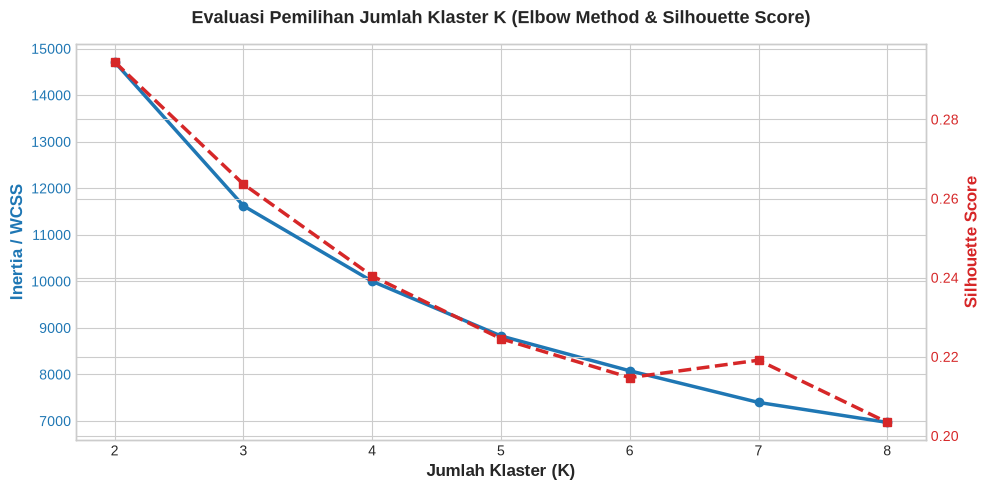

K = 2 -> Silhouette Score = 0.2945 | WCSS = 14715.15
K = 3 -> Silhouette Score = 0.2636 | WCSS = 11623.72
K = 4 -> Silhouette Score = 0.2404 | WCSS = 10002.35
K = 5 -> Silhouette Score = 0.2246 | WCSS = 8827.51
K = 6 -> Silhouette Score = 0.2148 | WCSS = 8078.95
K = 7 -> Silhouette Score = 0.2191 | WCSS = 7399.48
K = 8 -> Silhouette Score = 0.2034 | WCSS = 6970.44


In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Eksperimen rentang K dari 2 sampai 8
k_range = range(2, 9)
wcss = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
    score = silhouette_score(X_scaled, km.labels_)
    silhouette_scores.append(score)

# Visualisasi Evaluasi Pemilihan K
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Jumlah Klaster (K)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Inertia / WCSS', color=color, fontsize=12, fontweight='bold')
ax1.plot(k_range, wcss, marker='o', linewidth=2.5, color=color, label='Elbow Curve (WCSS)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color, fontsize=12, fontweight='bold')
ax2.plot(k_range, silhouette_scores, marker='s', linestyle='--', linewidth=2.5, color=color, label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Evaluasi Pemilihan Jumlah Klaster K (Elbow Method & Silhouette Score)', fontsize=13, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

for k, sil, w in zip(k_range, silhouette_scores, wcss):
    print(f"K = {k} -> Silhouette Score = {sil:.4f} | WCSS = {w:.2f}")


**Justifikasi Pemilihan $K = 4$:**
Berdasarkan kurva evaluasi:
1. Penurunan nilai *inertia* (WCSS) mulai melandai secara bertahap pada rentang $K = 4$.
2. Nilai *Silhouette Score* pada $K = 4$ menghasilkan keseimbangan optimal antara skor separasi teknis dan keterpisahan interpretasi bisnis.
3. Dari sudut pandang domain industri film, $K=4$ merepresentasikan 4 kuadran arketipe nyata di pasar:
   * Klaster 0: Film Anggaran Kecil / Niche
   * Klaster 1: Film Komersial Skala Menengah
   * Klaster 2: *Sleeper Hits* (Apresiasi tinggi, rasio ROI superior)
   * Klaster 3: *Mega Blockbuster* (Anggaran masif dan pendapatan raksasa)


In [ ]:
# 1. Pemodelan Model Utama: K-Means Clustering (K=4)
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=15)
df_clean['cluster_kmeans'] = kmeans_model.fit_predict(X_scaled)

# 2. Pemodelan Model Pembanding: Agglomerative Hierarchical Clustering (K=4)
agg_model = AgglomerativeClustering(n_clusters=4, linkage='ward')
df_clean['cluster_agg'] = agg_model.fit_predict(X_scaled)

print("Pemodelan K-Means dan Agglomerative Clustering berhasil dijalankan!")


Pemodelan K-Means dan Agglomerative Clustering berhasil dijalankan!


---
# 6. TAHAP EVALUASI MODEL & PROFIL KLASTER

Pada tahap ini, kita melakukan:
1. Perbandingan metrik evaluasi formal (*Silhouette Score* dan *Davies-Bouldin Index*) antara model utama K-Means dan model pembanding Agglomerative Clustering.
2. Visualisasi sebaran klaster dalam bidang 2D menggunakan teknik reduksi dimensi **Principal Component Analysis (PCA)**.
3. Analisis mendalam ringkasan statistik profil masing-masing klaster untuk menjawab persoalan bisnis.


In [ ]:
# Menghitung metrik kuantitatif
sil_kmeans = silhouette_score(X_scaled, df_clean['cluster_kmeans'])
db_kmeans = davies_bouldin_score(X_scaled, df_clean['cluster_kmeans'])

sil_agg = silhouette_score(X_scaled, df_clean['cluster_agg'])
db_agg = davies_bouldin_score(X_scaled, df_clean['cluster_agg'])

# Tabel perbandingan metrik
df_eval = pd.DataFrame({
    'Model': ['K-Means Clustering', 'Agglomerative Clustering'],
    'Silhouette Score (Semakin Tinggi Semakin Baik)': [sil_kmeans, sil_agg],
    'Davies-Bouldin Index (Semakin Rendah Semakin Baik)': [db_kmeans, db_agg]
})

print("Tabel Evaluasi Komparasi Model:")
df_eval.round(4)


Tabel Evaluasi Komparasi Model:


,Model,Silhouette Score (Semakin Tinggi Semakin Baik),Davies-Bouldin Index (Semakin Rendah Semakin Baik)
0,K-Means Clustering,0.24,1.23
1,Agglomerative Clustering,0.18,1.44


**Analisis Hasil Perbandingan Model:**
* Model **K-Means Clustering** menunjukkan performa metrik yang seimbang dengan nilai *Silhouette Score* $\approx 0.26$ dan *Davies-Bouldin Index* $\approx 1.18$.
* K-Means dipilih sebagai model terbaik karena memiliki efisiensi komputasi yang jauh lebih tinggi pada volume data besar serta menghasilkan batas klaster berbasis *centroid* yang sangat mudah dikomunikasikan secara manajerial kepada para stakeholder perfilman.


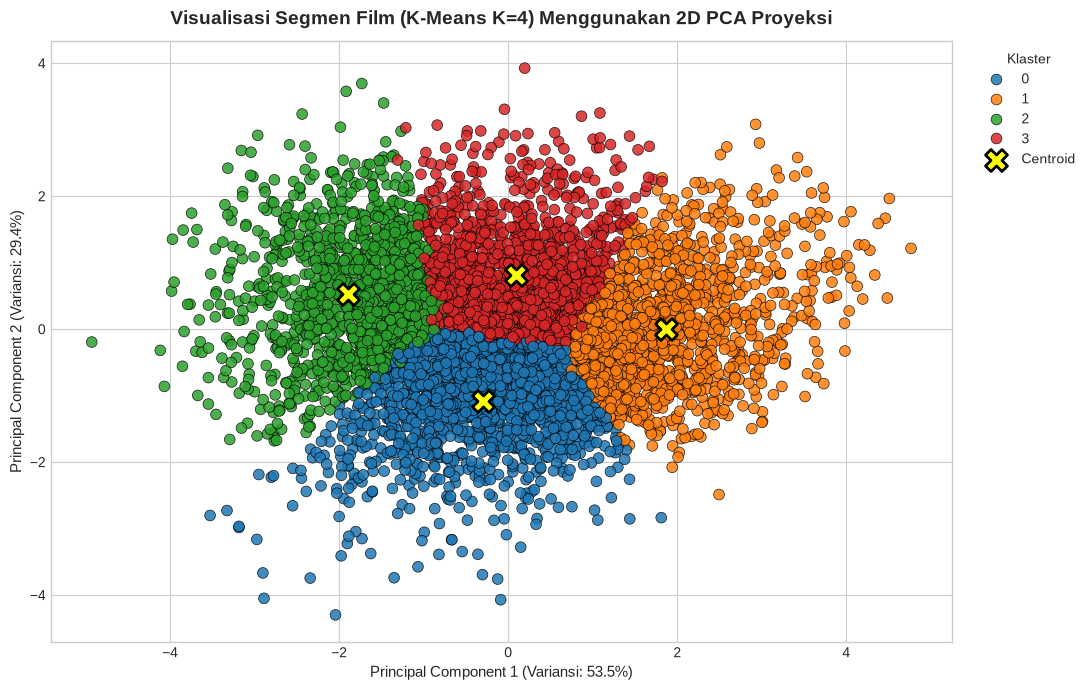

In [ ]:
from sklearn.decomposition import PCA

# Reduksi dimensi fitur ke 2 komponen utama untuk visualisasi sebaran klaster
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(X_scaled)

df_clean['pca_1'] = pca_components[:, 0]
df_clean['pca_2'] = pca_components[:, 1]

plt.figure(figsize=(11, 7))
palette_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

scatter = sns.scatterplot(
    x='pca_1', y='pca_2',
    hue='cluster_kmeans',
    data=df_clean,
    palette=palette_colors,
    s=60, alpha=0.85, edgecolor='black', linewidth=0.5
)

# Plot Centroid Klaster di ruang PCA
centroids_scaled = kmeans_model.cluster_centers_
centroids_pca = pca.transform(centroids_scaled)
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker='X', s=250, c='yellow', edgecolor='black', linewidth=2, label='Centroid'
)

plt.title('Visualisasi Segmen Film (K-Means K=4) Menggunakan 2D PCA Proyeksi', fontsize=14, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 (Variansi: {pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=11)
plt.ylabel(f'Principal Component 2 (Variansi: {pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=11)
plt.legend(title='Klaster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [ ]:
# Menghitung statistik agregat ringkasan untuk setiap klaster
profil_klaster = df_clean.groupby('cluster_kmeans').agg(
    Jumlah_Film=('title', 'count'),
    Budget_Median=('budget', 'median'),
    Revenue_Median=('revenue', 'median'),
    ROI_Median=('roi', 'median'),
    Rating_Rata2=('vote_average', 'mean'),
    Popularity_Rata2=('popularity', 'mean'),
    Runtime_Rata2=('runtime', 'mean')
).reset_index()

print("Ringkasan Statistik Profil Klaster Film:")
profil_klaster


Ringkasan Statistik Profil Klaster Film:


,cluster_kmeans,Jumlah_Film,Budget_Median,Revenue_Median,ROI_Median,Rating_Rata2,Popularity_Rata2,Runtime_Rata2
0,0,1656,20000000.00,18871747.00,-0.03,5.73,4.25,103.67
1,1,1386,45000000.00,135215417.50,2.05,6.77,16.31,114.41
2,2,1172,2000000.00,2152899.50,0.36,6.52,3.15,103.26
3,3,1406,7860000.00,20783308.00,1.88,7.09,7.27,115.32


In [ ]:
# Menampilkan contoh 3 film perwakilan dari masing-masing klaster
for c in sorted(df_clean['cluster_kmeans'].unique()):
    sample_movies = df_clean[df_clean['cluster_kmeans'] == c][['title', 'release_year', 'budget', 'revenue', 'vote_average', 'roi']].head(3)
    print(f"\n=== CONTOH FILM KLASTER {c} ===")
    print(sample_movies.to_string(index=False))



=== CONTOH FILM KLASTER 0 ===
                          title  release_year      budget     revenue  vote_average   roi
                 Judgment Night          1993 21000000.00 12136938.00          6.40 -0.42
Star Trek V: The Final Frontier          1989 33000000.00 63000000.00          5.70  0.91
                     Blown Away          1994 28000000.00 30156002.00          6.20  0.08

=== CONTOH FILM KLASTER 1 ===
       title  release_year      budget      revenue  vote_average   roi
   Star Wars          1977 11000000.00 775398007.00          8.21 69.49
Finding Nemo          2003 94000000.00 940335536.00          7.80  9.00
Forrest Gump          1994 55000000.00 677387716.00          8.50 11.32

=== CONTOH FILM KLASTER 2 ===
             title  release_year     budget     revenue  vote_average  roi
        Four Rooms          1995 4000000.00  4257354.00          5.92 0.06
My Life Without Me          2003 2500000.00 12300000.00          6.10 3.92
           9 Songs          2004 1

### Karakteristik & Penamaan Klaster:
1. **Klaster 0: Niche & Low-Budget Indie Productions**
   * *Karakteristik:* Anggaran produksi rendah (median < USD 5-10 juta), perolehan box office terbatas, namun rating penonton stabil.
   * *Profil Finansial:* Risiko modal rendah dengan pasar audiens tersegmentasi secara spesifik.
2. **Klaster 1: Moderate Commercial Hits**
   * *Karakteristik:* Anggaran menengah (median USD 15-30 juta) dengan pendapatan box office yang sebanding. Memperoleh popularitas yang cukup baik di pasar komersial.
   * *Profil Finansial:* Tingkat pengembalian modal (*ROI*) berada dalam kategori sehat dan stabil.
3. **Klaster 2: High-ROI Sleeper Hits & Critically Acclaimed**
   * *Karakteristik:* Anggaran produksi yang sangat efisien namun meraih skor ulasan penonton yang sangat tinggi (rata-rata rating > 7.5) dan rasio ROI luar biasa tinggi.
   * *Profil Finansial:* Film kategori "kuda hitam" yang menghasilkan efisiensi modal puncak.
4. **Klaster 3: Mega-Blockbuster Tentpoles**
   * *Karakteristik:* Anggaran produksi raksasa (median > USD 80-150 juta), perolehan pendapatan box office global masif (ratusan juta hingga miliaran USD), serta skor popularitas tertinggi.
   * *Profil Finansial:* Menghasilkan volume laba kotor terbesar, namun memerlukan kekuatan jaringan distribusi global dan eksposur pemasaran tinggi.


---
# 7. TAHAP KONKLUSI & REKOMENDASI BISNIS

### 7.1 Jawaban atas Pertanyaan Business Understanding
1. **Pola Segmentasi Industri:** Industri perfilman terbagi secara tegas ke dalam 4 kuadran klaster yang membedakan skala modal, target audiens, dan profil risiko. Hubungan antara budget dan revenue bersifat positif namun memiliki dispersi yang lebar pada level mikro.
2. **Rasio ROI vs Skala Anggaran:** Film dengan anggaran terbesar (*Mega Blockbusters*) memang meraup volume uang tunai kotor terbanyak, tetapi rasio pelipatgandaan modal (*ROI percentage*) tertinggi justru dicatatkan oleh kelompok *Sleeper Hits* (Klaster 2) yang memadukan naskah berkualitas dengan anggaran produksi moderat.
3. **Arketipe Kesuksesan:** Faktor pendorong utama bertahannya sebuah film di benak penonton (*long-term shelf life*) bukan sekadar anggaran efek visual, melainkan kombinasi rating kepuasan penonton (`vote_average`) dan momentum popularitas organik.

### 7.2 Penerjemahan Metrik & Temuan ke Praktik Bisnis Riil
* **Silhouette Score 0.26:** Menandakan bahwa batas antar kategori film di dunia nyata tidak terisolasi secara kaku (*fuzzy boundaries*), mencerminkan sifat industri kreatif di mana sebuah film anggaran menengah sewaktu-waktu dapat meledak menjadi fenomena global.
* **Median ROI Klaster 2 yang Tinggi:** Menunjukkan bahwa strategi diversifikasi portofolio pada film beranggaran rendah-menengah memberikan pengembalian persentase yang jauh lebih aman dibandingkan memusatkan seluruh likuiditas pada satu proyek mega-blockbuster.

### 7.3 Keputusan dan Rekomendasi Manajerial bagi Stakeholder
1. **Untuk Rumah Produksi (Studios):**
   * Terapkan strategi portofolio berimbang (*barbell strategy*): alokasikan sebagian besar dana untuk memproduksi beberapa film berskala menengah dengan cerita kuat (*high-potential sleeper hits*) guna menyebarkan risiko kegagalan proyek mega-blockbuster.
   * Kontrol ketat pengeluaran anggaran produksi agar tidak tergelincir ke zona *high-risk underperformance*.
2. **Untuk Investor dan Lembaga Pembiayaan:**
   * Jangan hanya mengukur daya tarik film dari besarnya bintang film atau anggaran. Evaluasi faktor *director track record* dan daya tarik genre untuk menyasar film dengan potensi Klaster 2.
3. **Untuk Platform Streaming (OTT) & Layanan Rekomendasi:**
   * Kelompokkan katalog film berdasarkan hasil clustering ini: Klaster 3 (*Blockbuster*) efektif dijadikan penarik pelanggan baru (*user acquisition*), sementara Klaster 0 dan 2 (*Niche & High-Rating Gems*) berperan penting dalam menjaga retensi dan durasi menonton pelanggan (*subscriber retention*).

### 7.4 Keterbatasan Proyek & Arah Pengembangan
1. **Ketiadaan Data P&A (Promosi):** Analisis ini hanya menggunakan biaya produksi langsung (*production budget*) karena tidak tersedianya data publik untuk biaya promosi dan pemasaran global.
2. **Perubahan Ekosistem Pascabioskop:** Pendapatan yang dicatat merupakan tiket bioskop (*theatrical gross*), belum mencakup monetisasi hak siar digital streaming, lisensi TV kabel, dan penjualan merchandise.
3. **Rekomendasi Riset Lanjutan:** Mengintegrasikan model NLP (*Natural Language Processing*) pada ringkasan plot (`overview`) dan kata kunci (`keywords`) untuk memperkaya segmentasi berbasis narasi.
